# Neo4j Graph Database Using Google Colab

Hands-on experiment: college knowledge graph with students, courses, instructors, and skills.

Dataset here uses a different set of students, courses, and instructors than the manual, but every step and command follows the same experiment.

## 1. Create a Neo4j AuraDB Instance

Done once, outside the notebook.

1. Open console.neo4j.io and sign in or create an account.
2. Choose Create Free Instance.
3. Save the generated password securely.
4. Wait for the instance to become available.
5. Copy the URI, username, and password from the connection details.

The URI begins with neo4j+s:// for a secure Aura connection. Never publish the password in a shared notebook or Git repository.

## 2. Install the Neo4j Driver

In [ ]:
!pip -q install neo4j

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 15.7 MB/s eta 0:00:00


## 3. Import Libraries

In [ ]:
from neo4j import GraphDatabase
from getpass import getpass
from pprint import pprint

## 4. Connect Google Colab to Neo4j

neo4j

Cb2CJgfaUzuhd4rP1JzhO-9dj3z4WKxindlfZ6sJ7KI

neo4j+s://16716e7d.databases.neo4j.io

In [ ]:
NEO4J_URI = input("Enter Neo4j URI: ")
NEO4J_USERNAME = input("Enter Neo4j username: ")
NEO4J_PASSWORD = getpass("Enter Neo4j password: ")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USERNAME, NEO4J_PASSWORD)
)
driver.verify_connectivity()
print("Neo4j connection successful.")

Enter Neo4j URI: neo4j+s://16716e7d.databases.neo4j.io
Enter Neo4j username: neo4j
Enter Neo4j password: ··········
Neo4j connection successful.


### Reusable Query Helper

In [ ]:
def run_query(query, parameters=None):
    with driver.session() as session:
        result = session.run(query, parameters or {})
        return [record.data() for record in result]

print(run_query("RETURN 1 AS test"))

[{'test': 1}]


## 5. Reset the Lab Graph

Deletes all nodes and relationships in the current Aura database. Use only at the start of a dedicated lab database.

In [ ]:
run_query("MATCH (n) DETACH DELETE n")
print("Existing graph data removed.")

Existing graph data removed.


## 6. Create Constraints and Indexes

In [ ]:
run_query("""
CREATE CONSTRAINT student_id_unique IF NOT EXISTS
FOR (s:Student) REQUIRE s.student_id IS UNIQUE
""")

run_query("""
CREATE CONSTRAINT course_code_unique IF NOT EXISTS
FOR (c:Course) REQUIRE c.code IS UNIQUE
""")

run_query("""
CREATE INDEX instructor_name_index IF NOT EXISTS
FOR (i:Instructor) ON (i.name)
""")

print(run_query("SHOW CONSTRAINTS"))
print(run_query("SHOW INDEXES"))

[{'id': 5, 'name': 'course_code_unique', 'type': 'UNIQUENESS', 'entityType': 'NODE', 'labelsOrTypes': ['Course'], 'properties': ['code'], 'ownedIndex': 'course_code_unique', 'propertyType': None}, {'id': 3, 'name': 'student_id_unique', 'type': 'UNIQUENESS', 'entityType': 'NODE', 'labelsOrTypes': ['Student'], 'properties': ['student_id'], 'ownedIndex': 'student_id_unique', 'propertyType': None}]
[{'id': 4, 'name': 'course_code_unique', 'state': 'ONLINE', 'populationPercent': 100.0, 'type': 'RANGE', 'entityType': 'NODE', 'labelsOrTypes': ['Course'], 'properties': ['code'], 'indexProvider': 'range-1.0', 'owningConstraint': 'course_code_unique', 'lastRead': None, 'readCount': None}, {'id': 1, 'name': 'index_1b9dcc97', 'state': 'ONLINE', 'populationPercent': 100.0, 'type': 'LOOKUP', 'entityType': 'RELATIONSHIP', 'labelsOrTypes': None, 'properties': None, 'indexProvider': 'token-lookup-1.0', 'owningConstraint': None, 'lastRead': None, 'readCount': 0}, {'id': 0, 'name': 'index_460996c0', 'sta

## 7. Create Nodes

### Students

In [ ]:
student_query = """
UNWIND $students AS student
MERGE (s:Student {student_id: student.student_id})
SET s.name = student.name,
    s.department = student.department,
    s.semester = student.semester,
    s.cgpa = student.cgpa,
    s.city = student.city
RETURN count(s) AS students_created
"""

students = [
    {"student_id": "CE101", "name": "Aditi Rao", "department": "Computer Engineering", "semester": 8, "cgpa": 8.9, "city": "Mumbai"},
    {"student_id": "CE102", "name": "Karan Mehta", "department": "Computer Engineering", "semester": 8, "cgpa": 9.4, "city": "Pune"},
    {"student_id": "CE103", "name": "Sneha Iyer", "department": "Information Technology", "semester": 7, "cgpa": 7.6, "city": "Bengaluru"},
    {"student_id": "CE104", "name": "Yash Verma", "department": "Computer Engineering", "semester": 6, "cgpa": 8.3, "city": "Nagpur"},
    {"student_id": "CE105", "name": "Meera Nair", "department": "Information Technology", "semester": 7, "cgpa": 9.0, "city": "Kochi"},
]

print(run_query(student_query, {"students": students}))

[{'students_created': 5}]


### Courses

In [ ]:
course_query = """
UNWIND $courses AS course
MERGE (c:Course {code: course.code})
SET c.title = course.title, c.credits = course.credits
RETURN count(c) AS courses_created
"""

courses = [
    {"code": "DS", "title": "Data Science", "credits": 4},
    {"code": "CN", "title": "Computer Networks", "credits": 3},
    {"code": "CC", "title": "Cloud Computing", "credits": 4},
    {"code": "ML", "title": "Machine Learning", "credits": 3},
]

print(run_query(course_query, {"courses": courses}))

[{'courses_created': 4}]


### Instructors and Skills

In [ ]:
run_query("""
CREATE (:Instructor {name: "Dr. Choudhury"}),
       (:Instructor {name: "Prof. Bhatt"}),
       (:Skill {name: "Java"}),
       (:Skill {name: "Neo4j"}),
       (:Skill {name: "Deep Learning"}),
       (:Skill {name: "Docker"})
""")

[]

## 8. Create Relationships

### Enrollments

In [ ]:
enrollment_query = """
UNWIND $enrollments AS e
MATCH (s:Student {student_id: e.student_id}), (c:Course {code: e.code})
MERGE (s)-[r:ENROLLED_IN]->(c)
SET r.marks = e.marks, r.semester = e.semester
"""

enrollments = [
    {"student_id": "CE101", "code": "DS", "marks": 88, "semester": 8},
    {"student_id": "CE102", "code": "DS", "marks": 95, "semester": 8},
    {"student_id": "CE103", "code": "DS", "marks": 70, "semester": 7},
    {"student_id": "CE101", "code": "CC", "marks": 79, "semester": 8},
    {"student_id": "CE105", "code": "CC", "marks": 90, "semester": 7},
    {"student_id": "CE104", "code": "ML", "marks": 81, "semester": 6},
    {"student_id": "CE102", "code": "ML", "marks": 92, "semester": 8},
    {"student_id": "CE103", "code": "CN", "marks": 74, "semester": 7},
    {"student_id": "CE104", "code": "CN", "marks": 68, "semester": 6},
]

run_query(enrollment_query, {"enrollments": enrollments})
print("Enrollments created.")

Enrollments created.


### Teaching Assignments

In [ ]:
teaches_query = """
UNWIND $teaches AS t
MATCH (i:Instructor {name: t.instructor}), (c:Course {code: t.code})
MERGE (i)-[:TEACHES]->(c)
"""

teaches = [
    {"instructor": "Dr. Choudhury", "code": "DS"},
    {"instructor": "Dr. Choudhury", "code": "CC"},
    {"instructor": "Prof. Bhatt", "code": "CN"},
    {"instructor": "Prof. Bhatt", "code": "ML"},
]

run_query(teaches_query, {"teaches": teaches})
print("Teaching assignments created.")

Teaching assignments created.


### Skills

In [ ]:
skill_query = """
UNWIND $skills AS sk
MATCH (s:Student {student_id: sk.student_id}), (skill:Skill {name: sk.skill})
MERGE (s)-[:HAS_SKILL]->(skill)
"""

skills = [
    {"student_id": "CE101", "skill": "Java"},
    {"student_id": "CE102", "skill": "Neo4j"},
    {"student_id": "CE103", "skill": "Deep Learning"},
    {"student_id": "CE104", "skill": "Java"},
    {"student_id": "CE105", "skill": "Neo4j"},
]

run_query(skill_query, {"skills": skills})
print("Skills linked.")

Skills linked.


### Prerequisite

In [ ]:
run_query("""
MATCH (a:Course {code: "CN"}), (b:Course {code: "DS"})
MERGE (a)-[:PREREQUISITE_OF]->(b)
""")
print("Prerequisite relationship created: CN -> DS")

Prerequisite relationship created: CN -> DS


## 9. Read and Traverse Graph Data

### All Students

In [ ]:
query = """
MATCH (s:Student)
RETURN s.student_id AS id, s.name AS name,
       s.department AS department, s.cgpa AS cgpa
ORDER BY s.cgpa DESC
"""
for row in run_query(query):
    pprint(row)

{'cgpa': 9.4,
 'department': 'Computer Engineering',
 'id': 'CE102',
 'name': 'Karan Mehta'}
{'cgpa': 9.0,
 'department': 'Information Technology',
 'id': 'CE105',
 'name': 'Meera Nair'}
{'cgpa': 8.9,
 'department': 'Computer Engineering',
 'id': 'CE101',
 'name': 'Aditi Rao'}
{'cgpa': 8.3,
 'department': 'Computer Engineering',
 'id': 'CE104',
 'name': 'Yash Verma'}
{'cgpa': 7.6,
 'department': 'Information Technology',
 'id': 'CE103',
 'name': 'Sneha Iyer'}


### Students Enrolled in Data Science

In [ ]:
query = """
MATCH (s:Student)-[r:ENROLLED_IN]->(c:Course {code: "DS"})
RETURN s.name AS student, r.marks AS marks, c.title AS course
ORDER BY marks DESC
"""
for row in run_query(query):
    pprint(row)

{'course': 'Data Science', 'marks': 95, 'student': 'Karan Mehta'}
{'course': 'Data Science', 'marks': 88, 'student': 'Aditi Rao'}
{'course': 'Data Science', 'marks': 70, 'student': 'Sneha Iyer'}


### Courses Taught by an Instructor

In [ ]:
query = """
MATCH (i:Instructor {name: "Dr. Choudhury"})-[:TEACHES]->(c:Course)
RETURN i.name AS instructor, c.code AS code, c.title AS course
"""
print(run_query(query))

[{'instructor': 'Dr. Choudhury', 'code': 'DS', 'course': 'Data Science'}, {'instructor': 'Dr. Choudhury', 'code': 'CC', 'course': 'Cloud Computing'}]


### Filter Using a Property

In [ ]:
query = """
MATCH (s:Student)
WHERE s.cgpa > 8.5
RETURN s.name AS name, s.cgpa AS cgpa
ORDER BY cgpa DESC
"""
print(run_query(query))

[{'name': 'Karan Mehta', 'cgpa': 9.4}, {'name': 'Meera Nair', 'cgpa': 9.0}, {'name': 'Aditi Rao', 'cgpa': 8.9}]


### Optional Match

In [ ]:
query = """
MATCH (s:Student)
OPTIONAL MATCH (s)-[:HAS_SKILL]->(skill:Skill)
RETURN s.name AS student, collect(skill.name) AS skills
"""
for row in run_query(query):
    pprint(row)

{'skills': ['Java'], 'student': 'Aditi Rao'}
{'skills': ['Neo4j'], 'student': 'Karan Mehta'}
{'skills': ['Deep Learning'], 'student': 'Sneha Iyer'}
{'skills': ['Java'], 'student': 'Yash Verma'}
{'skills': ['Neo4j'], 'student': 'Meera Nair'}


## 10. Update Operations

### Update a Node

In [ ]:
run_query("""
MATCH (s:Student {student_id: "CE101"})
SET s.cgpa = 9.1, s.city = "Thane"
RETURN s.name AS name, s.cgpa AS cgpa, s.city AS city
""")

[{'name': 'Aditi Rao', 'cgpa': 9.1, 'city': 'Thane'}]

### Update a Relationship Property

In [ ]:
run_query("""
MATCH (s:Student {student_id: "CE101"})-[r:ENROLLED_IN]->(c:Course {code: "DS"})
SET r.marks = 90
RETURN s.name AS student, c.code AS course, r.marks AS marks
""")

[{'student': 'Aditi Rao', 'course': 'DS', 'marks': 90}]

### Add a Relationship Safely with MERGE

In [ ]:
run_query("""
MATCH (s:Student {student_id: "CE101"}), (skill:Skill {name: "Docker"})
MERGE (s)-[:HAS_SKILL]->(skill)
""")

[]

## 11. Delete Operations

### Delete a Relationship

In [ ]:
run_query("""
MATCH (s:Student {student_id: "CE102"})-[r:HAS_SKILL]->(skill:Skill {name: "Neo4j"})
DELETE r
""")

[]

### Delete a Node with its Relationships

In [ ]:
run_query("""
MATCH (s:Student {student_id: "CE105"})
DETACH DELETE s
""")

[]

## 12. Aggregation

In [ ]:
query = """
MATCH (s:Student)
RETURN s.department AS department,
       count(s) AS student_count,
       round(avg(s.cgpa) * 100) / 100.0 AS average_cgpa
ORDER BY average_cgpa DESC
"""
for row in run_query(query):
    pprint(row)

{'average_cgpa': 8.93, 'department': 'Computer Engineering', 'student_count': 3}
{'average_cgpa': 7.6,
 'department': 'Information Technology',
 'student_count': 1}


## 13. More Graph Analytics

### Most Popular Courses

In [ ]:
query = """
MATCH (s:Student)-[:ENROLLED_IN]->(c:Course)
RETURN c.code AS course, c.title AS title,
       count(s) AS enrolled_students
ORDER BY enrolled_students DESC
"""
print(run_query(query))

[{'course': 'DS', 'title': 'Data Science', 'enrolled_students': 3}, {'course': 'ML', 'title': 'Machine Learning', 'enrolled_students': 2}, {'course': 'CN', 'title': 'Computer Networks', 'enrolled_students': 2}, {'course': 'CC', 'title': 'Cloud Computing', 'enrolled_students': 1}]


### Average Marks by Course

In [ ]:
query = """
MATCH (:Student)-[r:ENROLLED_IN]->(c:Course)
RETURN c.code AS course, round(avg(r.marks) * 100) / 100.0 AS average_marks
ORDER BY average_marks DESC
"""
print(run_query(query))

[{'course': 'ML', 'average_marks': 86.5}, {'course': 'DS', 'average_marks': 85.0}, {'course': 'CC', 'average_marks': 79.0}, {'course': 'CN', 'average_marks': 71.0}]


### Highest-Scoring Student in Each Course

In [ ]:
query = """
MATCH (s:Student)-[r:ENROLLED_IN]->(c:Course)
WITH c, s, r
ORDER BY r.marks DESC
WITH c, collect({student: s.name, marks: r.marks})[0] AS top
RETURN c.code AS course, top.student AS top_student, top.marks AS marks
ORDER BY c.code
"""
print(run_query(query))

[{'course': 'CC', 'top_student': 'Aditi Rao', 'marks': 79}, {'course': 'CN', 'top_student': 'Sneha Iyer', 'marks': 74}, {'course': 'DS', 'top_student': 'Karan Mehta', 'marks': 95}, {'course': 'ML', 'top_student': 'Karan Mehta', 'marks': 92}]


### Students Who Share a Skill

In [ ]:
query = """
MATCH (s1:Student)-[:HAS_SKILL]->(skill:Skill)<-[:HAS_SKILL]-(s2:Student)
WHERE s1.student_id < s2.student_id
RETURN s1.name AS student1, s2.name AS student2, skill.name AS shared_skill
"""
print(run_query(query))

[{'student1': 'Aditi Rao', 'student2': 'Yash Verma', 'shared_skill': 'Java'}]


### Shortest Path Example

In [ ]:
query = """
MATCH p = shortestPath(
    (a:Student {student_id: "CE101"})-[*..5]-(b:Course {code: "ML"})
)
RETURN [node IN nodes(p) | labels(node)[0] + ":" + coalesce(node.name, node.code)] AS path
"""
print(run_query(query))

[{'path': ['Student:Aditi Rao', 'Course:DS', 'Student:Karan Mehta', 'Course:ML']}]


## 14. Visualize the Graph in Colab

In [ ]:
!pip -q install networkx matplotlib

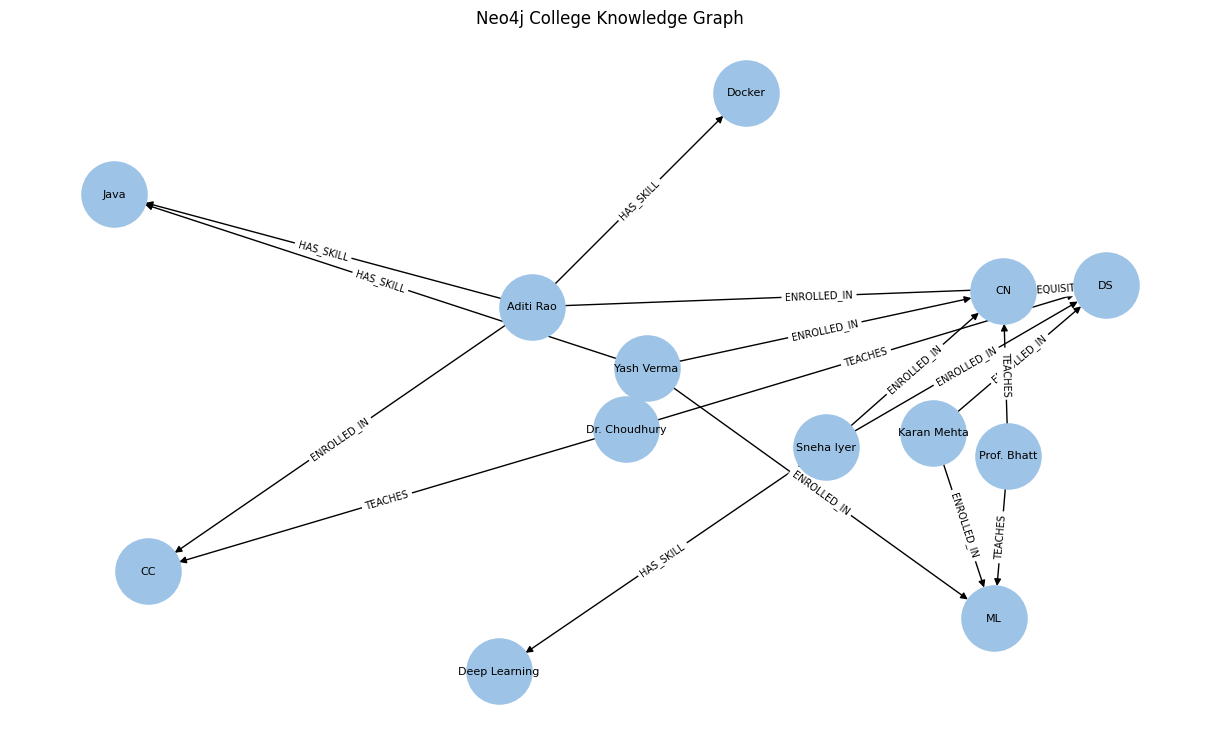

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

query = """
MATCH (a)-[r]->(b)
RETURN coalesce(a.name, a.code, a.student_id) AS source,
       type(r) AS relation,
       coalesce(b.name, b.code, b.student_id) AS target
LIMIT 30
"""
rows = run_query(query)

G = nx.DiGraph()
for row in rows:
    G.add_edge(row["source"], row["target"], label=row["relation"])

plt.figure(figsize=(12, 7))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color="#9DC3E6", node_size=2200,
        font_size=8, arrows=True)
nx.draw_networkx_edge_labels(G, pos,
    edge_labels={(u, v): d["label"] for u, v, d in G.edges(data=True)},
    font_size=7)
plt.title("Neo4j College Knowledge Graph")
plt.axis("off")
plt.show()

## 17. Cleanup

Use only at the end of a dedicated laboratory database -- this removes all data.

In [ ]:
driver.execute_query("MATCH (n) DETACH DELETE n")
driver.close()
print("Graph data removed and driver closed.")

Graph data removed and driver closed.
